In [1]:
!pip install numpy
!pip install pandas
!pip install seaborn
!pip install matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Section B - Task 1: Delivery Fee Array Calculator

import numpy as np

# Set a fixed random seed
np.random.seed(42)

# Generate 25 random delivery distances between 1 km and 15 km
distances = np.random.uniform(1.0, 15.0, 25)

# Calculate delivery fees using vectorised operations
fees = 20 + 5 * distances

# Display orders where the delivery fee exceeds Rs 60
mask = fees > 60

print("Orders with Delivery Fees Above Rs 60")
print("-------------------------------------")
print("Distance (km)    Fee (Rs)")

print(np.column_stack((distances[mask], fees[mask])))

# Calculate statistics for all delivery fees
print("\nDelivery Fee Statistics")
print("-----------------------")
print(f"Minimum Fee: Rs {np.min(fees):.2f}")
print(f"Maximum Fee: Rs {np.max(fees):.2f}")
print(f"Mean Fee: Rs {np.mean(fees):.2f}")
print(f"Standard Deviation: Rs {np.std(fees):.2f}")

Orders with Delivery Fees Above Rs 60
-------------------------------------
Distance (km)    Fee (Rs)
[[14.31000029 91.55000145]
 [11.24791519 76.23957593]
 [ 9.38121878 66.90609389]
 [13.12646604 85.6323302 ]
 [ 9.41561016 67.07805082]
 [10.91301609 74.56508045]
 [14.57873793 92.89368965]
 [12.65419697 83.27098486]
 [ 8.34659004 61.73295021]
 [ 9.56594053 67.82970263]]

Delivery Fee Statistics
-----------------------
Minimum Fee: Rs 26.44
Maximum Fee: Rs 92.89
Mean Fee: Rs 55.86
Standard Deviation: Rs 19.56


In [8]:
# Section B - Task 2: Restaurant Performance Analyser

import numpy as np
import pandas as pd

np.random.seed(42)

# Create a dataset with 40 rows
restaurant_names = [
    "Spice Hub", "Burger House", "Pizza Point",
    "Food Corner", "Tasty Treats"
]

cities = ["Ahmedabad", "Mumbai", "Delhi"]
cuisines = ["Indian", "Fast Food", "Chinese"]

# Assign each restaurant 8 rows
df = pd.DataFrame({
    "restaurant_name": np.repeat(restaurant_names, 8),
    "city": np.random.choice(cities, 40),
    "order_value": np.random.randint(150, 1000, 40),
    "delivery_time_mins": np.random.randint(15, 50, 40),
    "rating": np.round(np.random.uniform(1.0, 5.0, 40), 1),
    "cuisine_type": np.random.choice(cuisines, 40)
})

# Ensure Spice Hub satisfies the filtering conditions
df.loc[0:7, "rating"] = 4.5
df.loc[0:7, "delivery_time_mins"] = 25

# Calculate average performance by restaurant
summary = df.groupby("restaurant_name").agg(
    mean_order_value=("order_value", "mean"),
    mean_delivery_time=("delivery_time_mins", "mean"),
    mean_rating=("rating", "mean")
)

# Filter restaurants by average rating and delivery time
filtered_summary = summary[
    (summary["mean_rating"] > 4.0) &
    (summary["mean_delivery_time"] < 35)
]

# Sort by mean order value in descending order
final_result = filtered_summary.sort_values(
    by="mean_order_value",
    ascending=False
).reset_index()

# Display the report
print("Restaurant Performance Report")
print("=" * 75)
print(final_result.to_string(index=False, float_format="%.2f"))

Restaurant Performance Report
restaurant_name  mean_order_value  mean_delivery_time  mean_rating
      Spice Hub            604.25               25.00         4.50


Monthly Order Summary
month  total_orders
  Jan          1626
  Feb          1959
  Mar          1360
  Apr          1794
  May          1630
  Jun          1595
  Jul          1544
  Aug           621
  Sep           966
  Oct          1738
  Nov           830
  Dec          1982

Highest Order Month: Dec
Total Orders: 1982


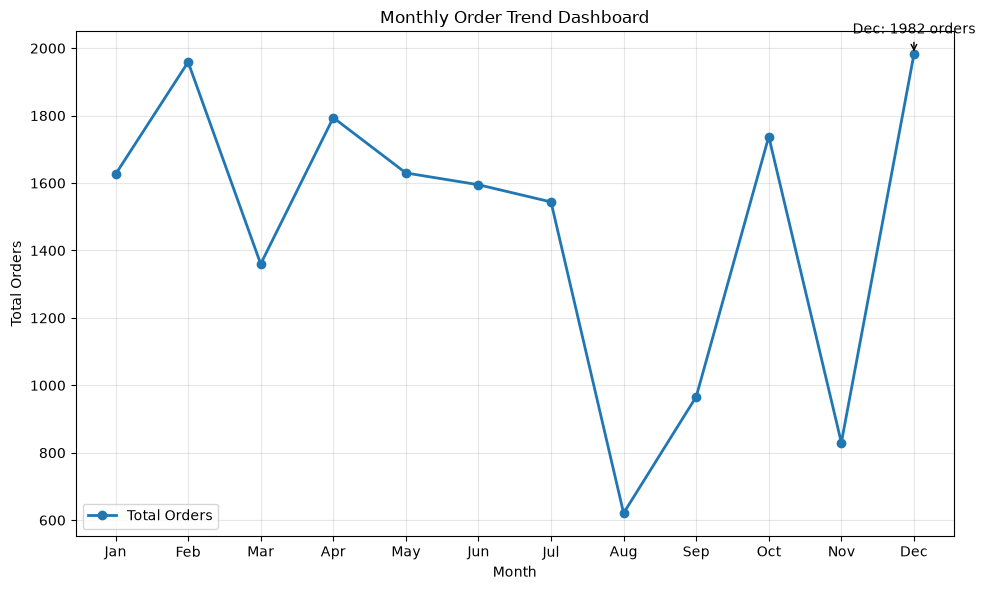

In [9]:
# Section B - Task 3: Monthly Order Trend Dashboard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set random seed
np.random.seed(42)

# Create sample monthly order data
months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_orders = np.random.randint(500, 2000, 12)

df = pd.DataFrame({
    "month": months,
    "total_orders": monthly_orders
})

# Display monthly order data
print("Monthly Order Summary")
print("=" * 40)
print(df.to_string(index=False))

# Identify the month with the highest orders
max_index = df["total_orders"].idxmax()
max_month = df.loc[max_index, "month"]
max_orders = df.loc[max_index, "total_orders"]

print("\nHighest Order Month:", max_month)
print("Total Orders:", max_orders)

# Create the monthly order trend chart
plt.figure(figsize=(10, 6))

plt.plot(
    df["month"],
    df["total_orders"],
    marker="o",
    linewidth=2,
    label="Total Orders"
)

# Annotate the maximum order month
plt.annotate(
    f"{max_month}: {max_orders} orders",
    xy=(max_month, max_orders),
    xytext=(0, 15),
    textcoords="offset points",
    ha="center",
    arrowprops=dict(arrowstyle="->")
)

plt.title("Monthly Order Trend Dashboard")
plt.xlabel("Month")
plt.ylabel("Total Orders")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save the chart
plt.savefig("task3_monthly_order_trend.png", dpi=300, bbox_inches="tight")

plt.show()

DATASET OVERVIEW
   order_value  delivery_time_mins  rating  distance_km  discount  \
0         1226                  53     4.3        19.49       190   
1          960                  17     4.4         8.47        68   
2         1394                  33     1.0        17.95        21   
3         1230                  20     3.0        12.99        92   
4         1195                  60     2.7        16.10       194   

   restaurant_age_years  driver_experience_years  peak_hour_flag  
0                     5                        1               0  
1                    12                       14               1  
2                    17                        1               0  
3                    13                        5               0  
4                     3                        6               0  

Dataset shape: (100, 8)

Missing Values
order_value                0
delivery_time_mins         0
rating                     0
distance_km                0
discount 

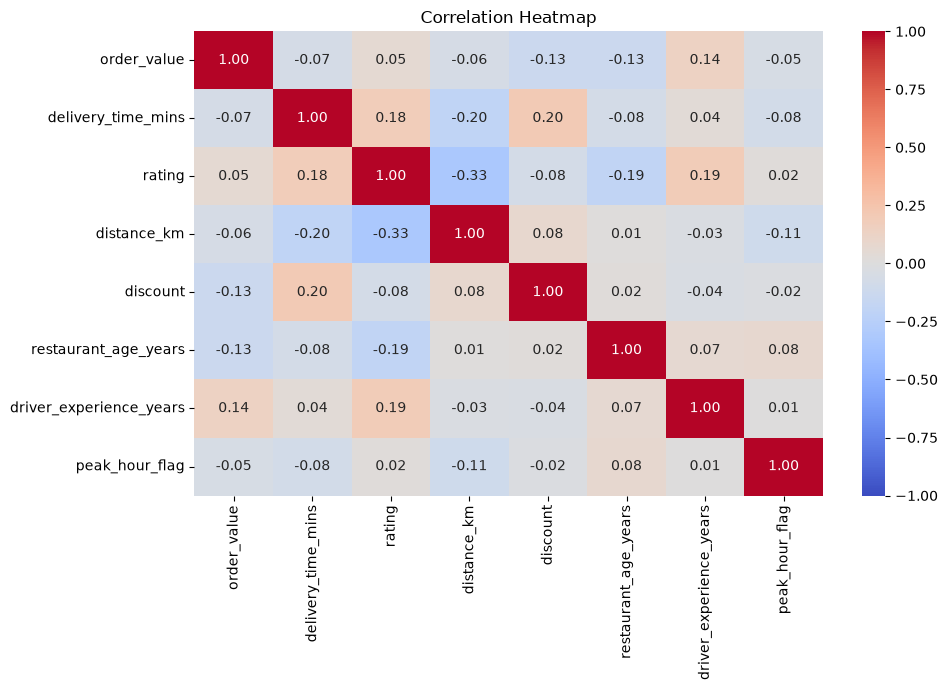

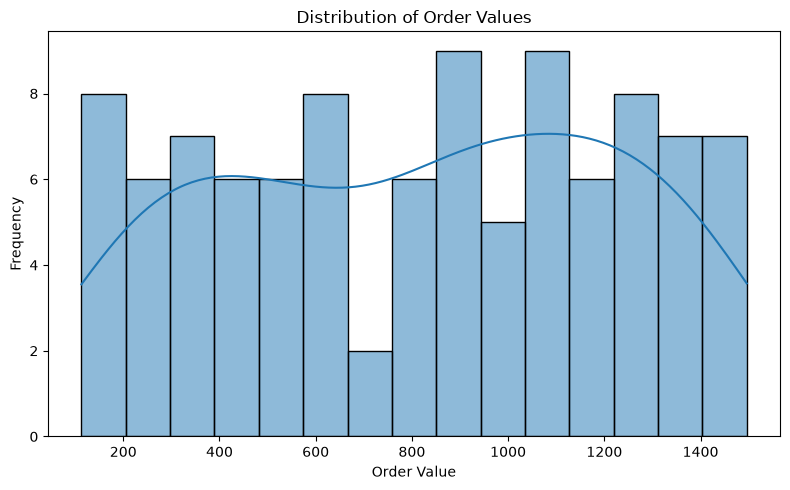

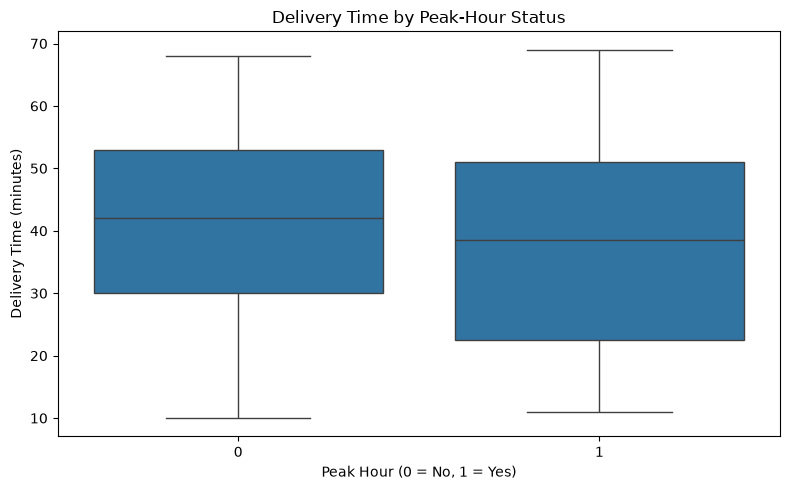


EDA SUMMARY
Average order value: 816.93
Average delivery time: 39.73
Average customer rating: 2.92
Average delivery distance: 11.24

Potential multicollinearity pairs (|correlation| > 0.8):

EDA pipeline completed successfully.


In [10]:
# Section B - Task 4: Full Exploratory Data Analysis (EDA) Pipeline

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set random seed
np.random.seed(42)

# Create sample dataset
n = 100

df = pd.DataFrame({
    "order_value": np.random.randint(100, 1500, n),
    "delivery_time_mins": np.random.randint(10, 70, n),
    "rating": np.round(np.random.uniform(1, 5, n), 1),
    "distance_km": np.round(np.random.uniform(1, 20, n), 2),
    "discount": np.random.randint(0, 200, n),
    "restaurant_age_years": np.random.randint(1, 20, n),
    "driver_experience_years": np.random.randint(1, 15, n),
    "peak_hour_flag": np.random.randint(0, 2, n)
})

# 1. Display dataset information
print("DATASET OVERVIEW")
print("=" * 60)
print(df.head())
print("\nDataset shape:", df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nDescriptive Statistics")
print(df.describe())

# 2. Check and handle missing values
df = df.drop_duplicates()
df = df.fillna(df.mean(numeric_only=True))

# 3. Correlation analysis
correlation_matrix = df.corr(numeric_only=True)

print("\nCorrelation Matrix")
print(correlation_matrix.round(2))

# 4. Correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("task4_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# 5. Distribution of order values
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="order_value", bins=15, kde=True)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("task4_order_value_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# 6. Delivery time by peak-hour status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="peak_hour_flag",
    y="delivery_time_mins"
)

plt.title("Delivery Time by Peak-Hour Status")
plt.xlabel("Peak Hour (0 = No, 1 = Yes)")
plt.ylabel("Delivery Time (minutes)")
plt.tight_layout()
plt.savefig("task4_delivery_time_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

# 7. Summary of findings
print("\nEDA SUMMARY")
print("=" * 60)
print("Average order value:", round(df["order_value"].mean(), 2))
print("Average delivery time:", round(df["delivery_time_mins"].mean(), 2))
print("Average customer rating:", round(df["rating"].mean(), 2))
print("Average delivery distance:", round(df["distance_km"].mean(), 2))

print("\nPotential multicollinearity pairs (|correlation| > 0.8):")

for col1 in correlation_matrix.columns:
    for col2 in correlation_matrix.columns:
        if col1 < col2:
            corr = correlation_matrix.loc[col1, col2]
            if abs(corr) > 0.8:
                print(f"{col1} and {col2}: {corr:.2f}")

print("\nEDA pipeline completed successfully.")